# First loading the cleaned CSV

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
file_path = input("Enter path to file:")

cleanDf = pd.read_csv(f'{file_path}/cicids2017_clean.csv')

# Now, the goal of this explority data analysis phase is two fold. Discover any buried artifacts remaining from the CICFlowMeter software that constructed this data. And uncover any key distinguishing features that might become useful in downstream prediction and charachterization. 

# With the above objective in mind we will first examine the 'Desination Port' column on a per class basis:

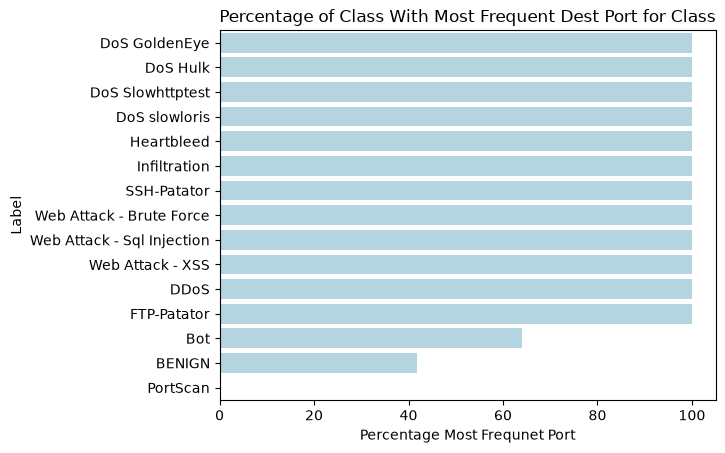

,Label,Destination Port With Max Count,Percentage of Label Records
3,DoS GoldenEye,80,100.000
4,DoS Hulk,80,100.000
5,DoS Slowhttptest,80,100.000
6,DoS slowloris,80,100.000
8,Heartbleed,444,100.000
9,Infiltration,444,100.000
11,SSH-Patator,22,100.000
12,Web Attack - Brute Force,80,100.000
13,Web Attack - Sql Injection,80,100.000
14,Web Attack - XSS,80,100.000


In [3]:
grouped_dest_port = cleanDf.groupby(by=['Label','Destination Port'])['Destination Port'].agg(['count']).reset_index()

# Also looking at the percentage of each class the most frequent class takes up.
label_top_dests = []

label_cnts = cleanDf.groupby('Label')['Label'].agg('count')

for label in grouped_dest_port['Label'].unique():
    
    temp_dest_sort = grouped_dest_port[grouped_dest_port['Label'] == label].sort_values(by='count',ascending=False).reset_index(drop=True)

    cnt = temp_dest_sort.loc[0,'count']
    port = temp_dest_sort.loc[0,'Destination Port']

    label_top_dests.append({'Label':label,'Destination Port With Max Count':port,'Percentage of Label Records':(cnt/label_cnts.loc[label])*100})

perc_unique_dest_port = pd.DataFrame(label_top_dests)
perc_unique_dest_port = perc_unique_dest_port.sort_values(by='Percentage of Label Records',ascending=False)

sns.barplot(y=perc_unique_dest_port['Label'],x=perc_unique_dest_port['Percentage of Label Records'],color='lightblue')
plt.xlabel('Percentage Most Frequnet Port')
plt.title('Percentage of Class With Most Frequent Dest Port for Class')
plt.show()

perc_unique_dest_port['Percentage of Label Records'] = perc_unique_dest_port['Percentage of Label Records'].apply(lambda x: f"{x:.3f}")
display(perc_unique_dest_port)


See this link for a cheat sheet of port meanings: https://networkproguide.com/common-ports-cheat-sheet/

In our proposed work we brought up the fact that multiple previous research groups came to the conclusion that the 'Source IP' and 'Destination IP' column in the original data could be nearly universally used to distingiush classes due to attacker hosts being fixed. But this begs the question, does the remaining 'Destination Port' column serve as a similar ultimantly meaningless non-generalizable feature? 

The PortScan class has only 0.410% of its entries actually having the most frequent destination port for that class. This signifies that the PortScan class is by far the most diverse when it comes to 'Destination Port', thus a downstream rule using 'Destination Port' as a paramater would be more likely to fail on the PortScan class. However, for the majority of the other classes their only destination port is 80 which makes sense as this corresponds to http traffic. So the artifact of the CIC testbead we are likely seeing here is a lack of target diversity, resulting in repetative destination ports. Another notable exception though to this lack of port diversity is the Bot class which has prt 8080 as its most frequent destination port, however, this is again more a artifact of the test bed as a Bot attack infects machines that are interneal to the victim network and thus the machines internal to the victim network have a larger port selection. Heartblead and Infiltration also use a different port (port 444) then the majority although all their flows still belong to a single destination port. 

Overall the story this chart tells is that the 'Destination Port' column is likely more a reflection of the testbead construction rather then any meaningful distinction for attack classes. However, with classes like SSH-Patator having a different port from 80 as its destination port if we keep this column in when performing AI algorithms we run the risk of 'Destination Port' being encoded as a signal when it really shouldn't be.

# Now we explore the Flow Duration feature and again discover another key artifact of this datasets construction through CCIC Flow Meter

## Bowley Skew

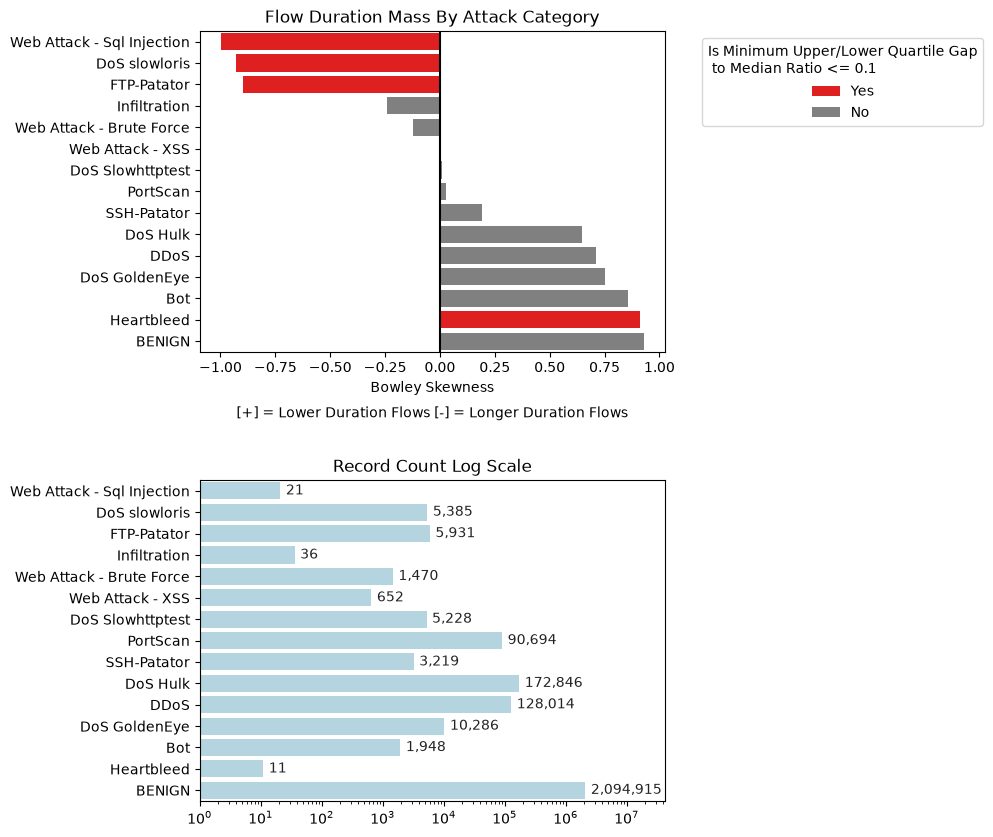

,Label,Bowley Skewness Val,Min Ratio,Max Flow Duration In S
0,Web Attack - Sql Injection,-0.998584,0.000708,5.086516
1,DoS slowloris,-0.928787,0.035813,119.046064
2,FTP-Patator,-0.895154,0.055321,10.780124
3,Infiltration,-0.242300,0.253108,119.995180
4,Web Attack - Brute Force,-0.124447,0.049505,35.451960
5,Web Attack - XSS,-0.001158,0.038283,70.203058
6,DoS Slowhttptest,0.010814,0.000587,119.800736
7,PortScan,0.028571,0.340000,119.809735
8,SSH-Patator,0.189874,0.043571,119.816717
9,DoS Hulk,0.648756,0.031269,119.968626


In [4]:
from matplotlib import pyplot as plt
import seaborn as sns
import scipy

from tqdm.auto import tqdm

tqdm.pandas()




def skew_pair_and_rat(s):
    q1, q2, q3 = s.quantile([.25, .5, .75])
    barley = ((q3-q2) - (q2-q1))/(q3-q1) if q3 > q1 else 2

    min_quart_gap = min((q2-q1),(q3-q2))

    quart_rat = None
    if q2 == 0:
        quart_rat = 0
    else:
        quart_rat = min_quart_gap / q2
        

    return(barley,quart_rat,np.abs(barley))



group_cnts = cleanDf[cleanDf['Flow Duration'] > 0].groupby('Label')['Flow Duration'].agg(['count','max']).reset_index()


def get_group_max(lab):
    temp_cnts = group_cnts[group_cnts['Label'] == lab].reset_index()
    return(temp_cnts.loc[0,'max'])


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 10),sharey=True)
plt.subplots_adjust(wspace=0.4, hspace=0.4)


bowley_vals = cleanDf[cleanDf['Flow Duration'] > 0].groupby('Label')['Flow Duration'].apply(skew_pair_and_rat)
bowley_vals = bowley_vals.apply(pd.Series)
bowley_vals.columns = ['Bowley Skewness Val','Min Ratio','Bowley Abs']
bowley_vals = bowley_vals.merge(group_cnts,on='Label')
bowley_vals = bowley_vals.sort_values(by='Bowley Skewness Val')

minum_range_rat =  0.1

bowley_vals['Low Mass Range'] = np.where( ( (bowley_vals['Bowley Abs'] >= 0.85) &  (bowley_vals['Min Ratio'] <= minum_range_rat) ), 'Yes', 'No')
bowley_vals['Low Mass Range'] = np.where( (bowley_vals['Bowley Abs'] == 2), 'Range Collapse', bowley_vals['Low Mass Range'] )
bowley_vals['Bowley Skewness Val'] =  np.where( (bowley_vals['Bowley Abs'] == 2), 0.1, bowley_vals['Bowley Skewness Val'] )
bowley_vals = bowley_vals.reset_index()
bowley_vals['Max Flow Duration In S'] = bowley_vals['Label'].apply(lambda x: get_group_max(x)/1000000)




sns.barplot(data=bowley_vals,x='Bowley Skewness Val',y='Label',hue='Low Mass Range',palette={'No': 'gray', 'Yes': 'red', 'Range Collapse': "#D9E80C"},ax=ax1)
sns.barplot(data=bowley_vals,y='Label',x='count',ax=ax2,color='lightblue')
ax2.set_xscale('log')
ax2.set_xlabel("")
ax2.set_title("Record Count Log Scale")

ax1.axvline(x=0,color="black")
ax1.set_title("Flow Duration Mass By Attack Category")
ax1.legend(title=f"Is Minimum Upper/Lower Quartile Gap\n to Median Ratio <= {minum_range_rat}",bbox_to_anchor=(1.7, 1))


ax1.set_xlabel("Bowley Skewness")

ax1.set_ylabel("")
ax2.set_ylabel("")
ax2.bar_label(ax2.containers[0],labels=[f'{val:,.0f}' for val in bowley_vals['count']],padding=4,color="#232326")
ax2.set_xlim(1,bowley_vals['count'].max()*20)


ax1.text(0.5, -0.17, "[+] = Lower Duration Flows [-] = Longer Duration Flows", 
        transform=ax1.transAxes, 
        ha='center', 
        va='top')


plt.show()



display(bowley_vals[['Label','Bowley Skewness Val','Min Ratio','Max Flow Duration In S']])

Next we explore skewness within the `Flow Duration` column, again separated out by attack class.

As will be demonstrated later, many of the flows pile up at the CICFlowMeter flow length cutoff of 120 seconds (https://github.com/ahlashkari/CICFlowMeter/blob/master/src/main/java/cic/cs/unb/ca/ifm/Cmd.java). Bowley, in conjunction with an additional flag, can make the presence of collapsed quartiles more obvious; a robust setup with the ability to expose the 120s cutoff artifact that is present. So, in conjunction with a high |Bowley| value, we use the formulation $\text{Min Ratio} = \frac{\text{min}(q_2-q_1,q_3-q_2)}{q_2}$ to detect classes where minimum quartile range has collapsed relative to the class's median Flow Duration.

With the above said, it helps to start with where our control BENIGN class lands on this chart. So this class's Bowley val is about 0.927, and its Min Ratio is nearly 1 at 0.99. What these two values show us is BENIGN has mostly low `Flow Duration` values, with even the narrower quartile gap having a notable range relative to the median.

In contrast, the Heartbleed class has a nearly as high Bowley value, at about 0.912, but has an extremely small Min Ratio value of 0.000014. With the ***|Bowley| >= 0.85 and Min Ratio <= 0.1*** threshold, this class is flagged because it has a high Bowley value, but its narrower quartile gap is minuscule compared to its median value. This class being flagged is not alone definitive proof that there is something wrong with it, but it is cause for further investigation.

Next, we have the 'Web Attack - Sql Injection', 'DoS slowloris', and 'FTP-Patator' being flagged as well, with high NEGATIVE Bowley values and low Min Ratio values. Three classes with skews towards higher duration flows, all being flagged for potential quartile range collapse, certainly warrant further investigation.

It is also interesting to note that two of our flagged classes ('Web Attack - Sql Injection', 'Heartbleed') have very few records, at 21 and 11, and extremely small Min Ratios. A small number of class points could lead to instability in skewness measures. However, with other classes, such as 'DoS slowloris' being flagged with 5,385 points, there is likely more to the story and further investigation of the flagged classes is needed.

Overall, this figure reveals meaningful differences in `Flow Duration` skew between classes and gives direction for further investigation.

# Heartbleed class investigation in Flow Duration

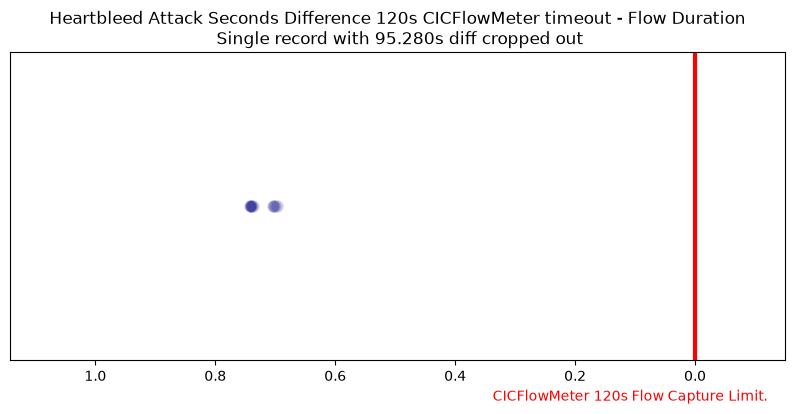

,Flow Duration,Second Difference; 120s CICFLowMeter Flow Timeout - Flow Duration
0,119.302728,0.697272
1,119.299621,0.700379
2,119.297996,0.702004
3,119.296592,0.703408
4,119.262215,0.737785
5,119.261118,0.738882
6,119.260295,0.739705
7,119.259886,0.740114
8,119.259012,0.740988
9,119.257653,0.742347


In [5]:
heartbleed_test = cleanDf[cleanDf['Label'] == 'Heartbleed'][['Flow Duration','Destination Port']].reset_index(drop=True)
heartbleed_test['Flow Duration'] = heartbleed_test['Flow Duration'].apply(lambda x: x / 1000000)
heartbleed_test['Wall_Diff'] = 120 - heartbleed_test['Flow Duration']


q1 = heartbleed_test['Flow Duration'].quantile(q=0.25)
q2 = heartbleed_test['Flow Duration'].quantile(q=0.5)
q3 = heartbleed_test['Flow Duration'].quantile(q=0.75)

heartbleed_test = heartbleed_test.sort_values(by='Wall_Diff').reset_index(drop=True)
heartbleed_test['y'] = np.zeros(11)


fig, ax1 = plt.subplots(1, 1, figsize=(10, 4),sharey=True)

sns.scatterplot(data=heartbleed_test,x='Wall_Diff',y='y',s=80,alpha=0.2,color="navy")
ax1.axvline(x=0,lw=3,color='red')

ax1.set_xlim((-0.15,heartbleed_test.loc[9,'Wall_Diff']+0.4))
ax1.set_xlabel("CICFlowMeter 120s Flow Capture Limit.",color="red")

ax1.set_yticks([])
ax1.set_ylabel("")

ax1.xaxis.label.set_position((0.8,0))
ax1.set_title(f"Heartbleed Attack Seconds Difference 120s CICFlowMeter timeout - Flow Duration\n Single record with {heartbleed_test.loc[10,'Wall_Diff']:.3f}s diff cropped out")
ax1.invert_xaxis()


plt.show()


display_tbl = heartbleed_test[['Flow Duration','Wall_Diff']]
display_tbl.columns = ['Flow Duration','Second Difference; 120s CICFLowMeter Flow Timeout - Flow Duration ']

display(display_tbl)

Now, digging deeper into the Heartbleed class, we see an interesting pattern: all but one of the Heartbleed data points fall within a tight cluster roughly 0.7 seconds of the 120s flow record timeout. Furthermore, the whole cluster shown in the scatter plot above spans $0.742347 - 0.697272 \approx 0.045$ seconds out of the roughly 119-second length of most Heartbleed flows. The clusters' narrow duration timing and proximity to the 120-second timeout suggest an intriguing interaction between the Heartbleed attack mechanics and CICFlowMeter.

A Heartbeat is a mechanism in the OpenSSL library that allows connected peers to verify the continued presence of one another. One of the peers initiates a Heartbeat request. Each Heartbeat has a payload for the sake of verification and a claimed size of that payload. The attacker can get the server to reveal sensitive information by copying out more of its memory than the length of the originally intended response by exploiting an unchecked claimed payload size. Because the attacker does not know what will come back, they must send this Heartbeat request many times. The continued Heartbeat keeps the single connection alive, avoiding the cost of initiating a new connection every time.

So, one possible interpretation of the plot above: The 120-second duration timeout leads to what is semantically one unified attack flow being broken up into multiple distinct flow records. With a 24-second leftover at some point over the course of the attack.

https://www.csoonline.com/article/562859/the-heartbleed-bug-how-a-flaw-in-openssl-caused-a-security-crisis.html

# Verifying the 120 second timeout.

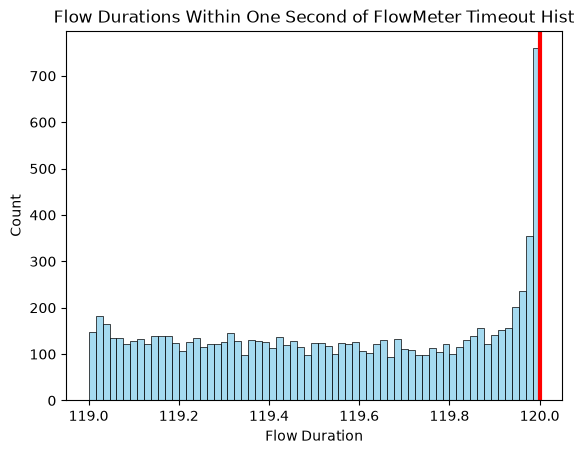

,Label,Percent at Threshold
5,Heartbleed,90.909091
6,Infiltration,19.444444
4,DoS slowloris,0.798514
3,DoS Slowhttptest,0.535578
0,BENIGN,0.430328
1,DoS GoldenEye,0.097220
8,SSH-Patator,0.062131
2,DoS Hulk,0.034713
7,PortScan,0.001103


In [6]:
orig_class_cnt_df = cleanDf.groupby(by='Label')['Flow Duration'].agg(['count'])
orig_class_cnt_df.columns=['count_orig']

flow_threshold_df = cleanDf[cleanDf['Flow Duration'] > (120000000 - 1000000)].reset_index(drop=True)
flow_threshold_df['Flow Duration'] = flow_threshold_df['Flow Duration'].apply(lambda x: x / 1000000)
flow_threshold_grouped = flow_threshold_df.groupby(by='Label')['Flow Duration'].agg(['count']).reset_index()

def calc_perc(x):
    lab = x['Label']
    cnt_thresh = x['count']

    return((cnt_thresh/orig_class_cnt_df.loc[lab,'count_orig'])*100)

flow_threshold_grouped['Percent at Threshold'] = flow_threshold_grouped.apply(calc_perc,axis=1)
flow_threshold_grouped = flow_threshold_grouped[['Label','Percent at Threshold']]

# thresholded_classes = flow_threshold_df['Label'].to_list()

# orig_class_cnt_df = orig_class_cnt_df[orig_class_cnt_df['Label'] in thresholded_classes]



#flow_threshold_by_class = flow_threshold_df.join(orig_class_cnt_df)

sns.histplot(data=flow_threshold_df,x='Flow Duration',color="skyblue",bins=65)
plt.axvline(x=120,color='red',lw=3)
plt.title('Flow Durations Within One Second of FlowMeter Timeout Hist')
plt.show()

display(flow_threshold_grouped.sort_values(by="Percent at Threshold",ascending=False))



So, as seen in the CICFlowMeter code here https://github.com/ahlashkari/CICFlowMeter/blob/master/src/main/java/cic/cs/unb/ca/ifm/Cmd.java (`long flowTimeout = 120000000L;` that's microseconds), it is a fact that the tool used to construct this dataset has a limit on the duration of a single flow. The question is, are the effects of this noticeable on the dataset at a broad level, or is the majority of the dataset unaffected?

The histogram visualizes the distribution of all data points whose flow duration falls within one second of the 120s timeout. The table shows the percentage of a class's points that have flow durations near the timeout. Only classes with non-zero percentages are shown in the table.

The histogram shows that the 120-second timeout does have an impact on our dataset. The table shows this impact is disproportionate between classes. Heartbleed gets hit by far the hardest, with about 90.9 percent of its points falling within one second of the timeout. Contrast this effect with classes like PortScan, which has about 0.0011 percent of its flows falling within one second of the timeout. So this disproportionate effect might distort the reality of some classes more than others.

# Looking at DoS slowloris

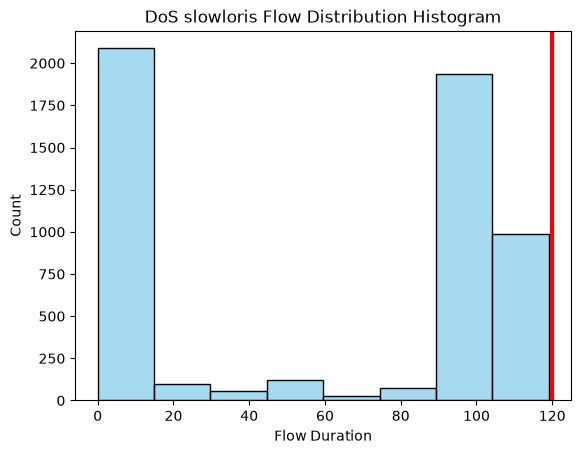

In [7]:
dos_slow_test = cleanDf[cleanDf['Label'] == 'DoS slowloris' ]
dos_slow_test['Flow Duration'] = dos_slow_test['Flow Duration'].apply(lambda x: x / 1000000)


sns.histplot(data=dos_slow_test,x='Flow Duration',color="skyblue",bins=8)
plt.axvline(x=120,color='red',lw=3)
plt.title('DoS slowloris Flow Distribution Histogram')
plt.show()

The above histogram shows the distribution of `Flow Duration` specifically for the 'DoS slowloris' class, with a vertical red line for the timeout on the right.

Overall, we see a notable bimodal distribution here with a frequency peak at the lower end of duration, a sparse plain, and then another frequency peak at the higher end.

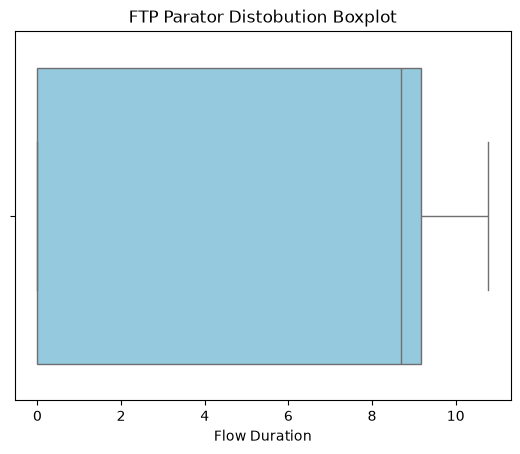

In [8]:
ftp_par_test = cleanDf[cleanDf['Label'] == 'FTP-Patator' ]
ftp_par_test['Flow Duration'] = ftp_par_test['Flow Duration'].apply(lambda x: x / 1000000)

sns.boxplot(data=ftp_par_test,x='Flow Duration',color='skyblue')
plt.title('FTP Parator Distobution Boxplot')
plt.show()

The above boxplot for `Flow Duration` of the FTP-Patator class shows an interesting distribution. The IQR, denoted by the box width, shows a range of roughly 9.7 seconds. However, the range between $q_1$ and $q_2$ is massive compared to the range between $q_2$ and $q_3$: $q_2-q_1 \approx 8.9-0 \approx 8.9$, while $q_3-q_2 \approx 9.7 - 8.9 \approx 0.8$. So this is the exact kind of quartile range collapse our flag in the Bowley visual was designed to catch. So while the range between $q_2$ and $q_3$ is dense, we can say that this is a genuine characteristic of the class, as the max flow duration remains well below the timeout at about 10.78 seconds.

# Conclusion

Overall, this exploratory data analysis revealed potential artifacts of the CICFlowMeter tool and the experimental testbed seeping into the major characteristics of the dataset itself. 

We saw a lack of `Destination Port` variety for different classes in the first visual, with all but three classes' data points being above 99% in a single `Destination Port`. So the question is then: is the destination port something that has the potential to be generalizable outside of this dataset? Or is the `Destination Port` purely an artifact of the testbed behind this dataset's construction that should be dropped?

Additionally, the `Flow Duration` column seems to be a potential signal that could be used to separate classes. However, the question is whether a predictor can separate out noise as a fallout of this 120-second timeout. Furthermore, how could other dataset features be affected by this flow fragmentation? Especially for classes such as Heartbleed, where a majority of its points sit against this timeout wall. What we can do in light of this issue is provide this as an honest caveat in our model performance.